# PTB-XL — Enhanced EDA and 12-Lead Preprocessing Analysis

This notebook improves the uploaded `rundata.ipynb` while keeping its main workflow: **dataset-wide metadata analysis**, followed by **one representative 12-lead ECG recording** for detailed waveform analysis. It intentionally does **not** generate 21,799 individual waveform figures.

**Output sections:** (1) data dictionary, (2) demographic and diagnostic EDA, (3) sample waveform, (4) raw versus filtered ECG for all 12 leads, (5) removed components/residuals, (6) raw versus filtered Welch power spectra, (7) quantitative per-lead processing effects, (8) morphology zoom, (9) lead-correlation comparison.

**Required packages:** `pip install numpy pandas matplotlib scipy torch wfdb ipython`. Set `BASE_DIR` in the next cell to the directory containing `ptbxl_database.csv`, `scp_statements.csv`, and `records100` (or `records500`).

**Scientific limitations:** Sample waveform conclusions apply to the **selected ECG**, not all patients; annotations from a complete recording must not automatically be treated as prior diagnoses. Zero-phase filtering and whole-record normalization below are for **offline EDA only**, *not* for deployment or leakage-safe forecasting.

In [2]:
from pathlib import Path
import ast
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import butter, sosfiltfilt, welch
import torch
from IPython.display import display

BASE_DIR = Path('PTB-XL')       # Change to your dataset directory
OUTPUT_DIR = Path('ptbxl_eda_outputs')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
USE_500HZ = False            # False=100 Hz, True=500 Hz
ECG_ID = None                # Set an ECG ID to inspect it; None selects first row
LOWCUT, HIGHCUT = 0.5, 40.0  # Hz; exploratory filter, NOT an invariant clinical standard
LEADS = ['I','II','III','aVR','aVL','aVF','V1','V2','V3','V4','V5','V6']

meta_file = BASE_DIR / 'ptbxl_database.csv'
scp_file = BASE_DIR / 'scp_statements.csv'
if not meta_file.exists() or not scp_file.exists():
    raise FileNotFoundError(
        f'PTB-XL metadata not found in {BASE_DIR.resolve()}. '
        'Set BASE_DIR to the extracted PTB-XL v1.0.3 folder.'
    )
df = pd.read_csv(meta_file).set_index('ecg_id', verify_integrity=True)
df_scp = pd.read_csv(scp_file, index_col=0)
df_scp.index = df_scp.index.astype(str)

print('Records:', len(df), '| Unique patients:', df.patient_id.nunique())
print('Fold distribution:', df.strat_fold.value_counts().sort_index().to_dict())
print('Data location:', BASE_DIR.resolve())

Records: 21799 | Unique patients: 18869
Fold distribution: {1: 2175, 2: 2181, 3: 2192, 4: 2174, 5: 2174, 6: 2173, 7: 2176, 8: 2173, 9: 2183, 10: 2198}
Data location: /Users/omarfaruk/Desktop/codex-practice/ecg/ptbxl-patient-conditioned-ecg-forecasting/PTB-XL


## 1 · Data dictionary: original PTB-XL metadata

The 28 fields in `ptbxl_database.csv` are catalogued below, including units and recommended use. `ecg_id` is an index; signal measurements are stored separately in WFDB files (not in metadata columns). Missing-value percentages in the generated table are computed from **your installed dataset**, rather than assumed.

The data dictionary is also exported as `ptbxl_eda_outputs/PTBXL_Data_Dictionary.csv` after running the code. [PTB-XL documentation](https://physionet.org/content/ptb-xl/1.0.3/).

In [3]:
# Fields: category, column, unit_or_type, meaning, recommended_use
DATA_DICTIONARY = [('Identifiers', 'ecg_id', 'Integer', 'Unique ECG recording identifier', 'Index/joins, not a predictor'), ('Identifiers', 'patient_id', 'Integer', 'Pseudonymous unique patient identifier', 'Patient-isolated splitting only'), ('Identifiers', 'filename_lr', 'Path string', 'WFDB record path at 100 Hz', 'Load signal, not a predictor'), ('Identifiers', 'filename_hr', 'Path string', 'WFDB record path at 500 Hz', 'Load signal, not a predictor'), ('General', 'age', 'Years', 'Age at time of recording', 'Static feature; fit imputation on train'), ('General', 'sex', 'Code', 'Recorded sex (0=male, 1=female)', 'Static feature; encode missingness'), ('General', 'height', 'cm', 'Height in centimeters', 'Optional static feature; many missing'), ('General', 'weight', 'kg', 'Weight in kilograms', 'Optional static feature; many missing'), ('General', 'nurse', 'Category', 'Pseudonymized recording nurse', 'Audit site/operator confounding'), ('General', 'site', 'Category', 'Pseudonymized acquisition site', 'Audit site differences; cautious modeling'), ('General', 'device', 'Category', 'ECG acquisition device model', 'Device-stratified robustness analysis'), ('General', 'recording_date', 'Date-time', 'Recorded ECG acquisition date/time', 'Chronology audit; not routine predictor'), ('ECG statements', 'report', 'Text', 'Cardiologist/automatic textual interpretation', 'Do not use as current-record forecast input'), ('ECG statements', 'scp_codes', 'Dictionary', 'SCP-ECG code → diagnostic likelihood', 'Labels for descriptive EDA; current-record leakage risk'), ('ECG statements', 'heart_axis', 'Category', 'Recorded electrical heart axis', 'Avoid as future-derived predictor'), ('ECG statements', 'infarction_stadium1', 'Category', 'First infarction stage annotation', 'Not input without verified prior availability'), ('ECG statements', 'infarction_stadium2', 'Category', 'Second infarction stage annotation', 'Not input without verified prior availability'), ('ECG statements', 'validated_by', 'Category', 'Pseudonymized validating cardiologist', 'Annotation provenance; not predictor'), ('ECG statements', 'second_opinion', 'Boolean', 'Second (potentially differing) opinion flag', 'Annotation quality audit'), ('ECG statements', 'initial_autogenerated_report', 'Boolean', 'Flag: initial machine-generated report', 'Annotation provenance'), ('ECG statements', 'validated_by_human', 'Boolean', 'Human validation flag', 'Annotation quality audit'), ('Signal quality', 'baseline_drift', 'Text/category', 'Annotation indicating baseline drift or jumps', 'Signal-quality EDA, not prospective input'), ('Signal quality', 'static_noise', 'Text/category', 'Annotation indicating static/electrical noise', 'Quality EDA, not prospective input'), ('Signal quality', 'burst_noise', 'Text/category', 'Annotation indicating transient bursts of noise', 'Quality EDA, not prospective input'), ('Signal quality', 'electrodes_problems', 'Text/category', 'Recorded electrode problems', 'Quality EDA, not prospective input'), ('Signal quality', 'extra_beats', 'Text/category', 'Annotation of extra/systolic beats', 'Quality EDA; target information risk'), ('Signal quality', 'pacemaker', 'Text/category', 'Annotation of pacemaker patterns', 'Not necessarily known before prediction'), ('Splitting', 'strat_fold', 'Integer (1–10)', 'Official patient-isolated stratified CV fold', 'Folds 1–8 train; 9 val; 10 test')]

schema = pd.DataFrame(DATA_DICTIONARY, columns=[
    'group','column','type_or_unit','description','research_use'
])
metadata_fields = ['ecg_id'] + list(df.columns)
schema['present_in_dataset'] = schema['column'].isin(metadata_fields)
schema['missing_pct'] = schema['column'].map(
    df.isna().mean().mul(100).round(2).to_dict()
).fillna(0.0)
schema['nonmissing_count'] = schema['column'].map(df.notna().sum().to_dict())
schema.loc[schema['column']=='ecg_id', 'nonmissing_count'] = len(df)
schema['nonmissing_count'] = schema['nonmissing_count'].fillna(0).astype(int)
schema.to_csv(OUTPUT_DIR / 'PTBXL_Data_Dictionary.csv', index=False)
display(schema)

if not schema.present_in_dataset.all():
    print('WARNING: Unexpected missing columns:', schema.loc[~schema.present_in_dataset, 'column'].tolist())

,group,column,type_or_unit,description,research_use,present_in_dataset,missing_pct,nonmissing_count
0,Identifiers,ecg_id,Integer,Unique ECG recording identifier,"Index/joins, not a predictor",True,0.00,21799
1,Identifiers,patient_id,Integer,Pseudonymous unique patient identifier,Patient-isolated splitting only,True,0.00,21799
2,Identifiers,filename_lr,Path string,WFDB record path at 100 Hz,"Load signal, not a predictor",True,0.00,21799
3,Identifiers,filename_hr,Path string,WFDB record path at 500 Hz,"Load signal, not a predictor",True,0.00,21799
4,General,age,Years,Age at time of recording,Static feature; fit imputation on train,True,0.00,21799
5,General,sex,Code,"Recorded sex (0=male, 1=female)",Static feature; encode missingness,True,0.00,21799
6,General,height,cm,Height in centimeters,Optional static feature; many missing,True,68.01,6974
7,General,weight,kg,Weight in kilograms,Optional static feature; many missing,True,56.78,9421
8,General,nurse,Category,Pseudonymized recording nurse,Audit site/operator confounding,True,6.76,20326
9,General,site,Category,Pseudonymized acquisition site,Audit site differences; cautious modeling,True,0.08,21782


### Data dictionary: waveform and derived model features

| Field / object | Shape / units | Derivation | Correct use |
|---|---|---|---|
| `signal` | `[T, 12]` in **mV** | `wfdb.rdsamp` | Raw 12-lead measurement |
| `tensor_signal` | `[12, T]` in mV | PyTorch channel-first | Model/EDA dynamic input |
| `filtered_tensor` | `[12, T]` in mV | 0.5–40 Hz zero-phase bandpass | **Exploratory visual analysis** only |
| `processed_tensor` | `[12, T]` z-score | Per-record filter then normalization | **Visualization only**, can leak for forecasting |
| `height`, `weight`, age and sex | Patient metadata | Optional static branch | Train-only imputation and scaling |
| `bmi` | kg/m² | Weight / (height in m)² | Use only if both measurements valid; add missingness flag |
| `heart_rate_bpm`, `mean_rr_seconds` | bpm, seconds | Detect beats only in **observed input window** | Candidate dynamic-derived conditioning features; include validity flag |
| `historical_diagnosis` | Multi-hot | Only from verified earlier record | Exclude current-record `scp_codes` from forecasting input |
| `y_future` | `[12, H]` in mV | Later segment of same ECG record | Forecast target; never use to compute input normalization |

This notebook demonstrates **signal exploration**, not a trained forecasting experiment. Report downstream train/validation/test performance separately.

## 2 · Dataset-wide demographics, diagnostics, missingness and folds

Plots in this section are computed using **all metadata rows**. Diagnostic superclass bars use multi-label membership, so a record may contribute to several categories and totals need not equal the number of ECGs.

Diagnostic superclass counts (multi-label):
NORM    9514
MI      5469
STTC    5235
CD      4898
HYP     2649
Records with no diagnostic superclass: 411
Counts by recorded sex (0=male, 1=female):
sex
0    11354
1    10445


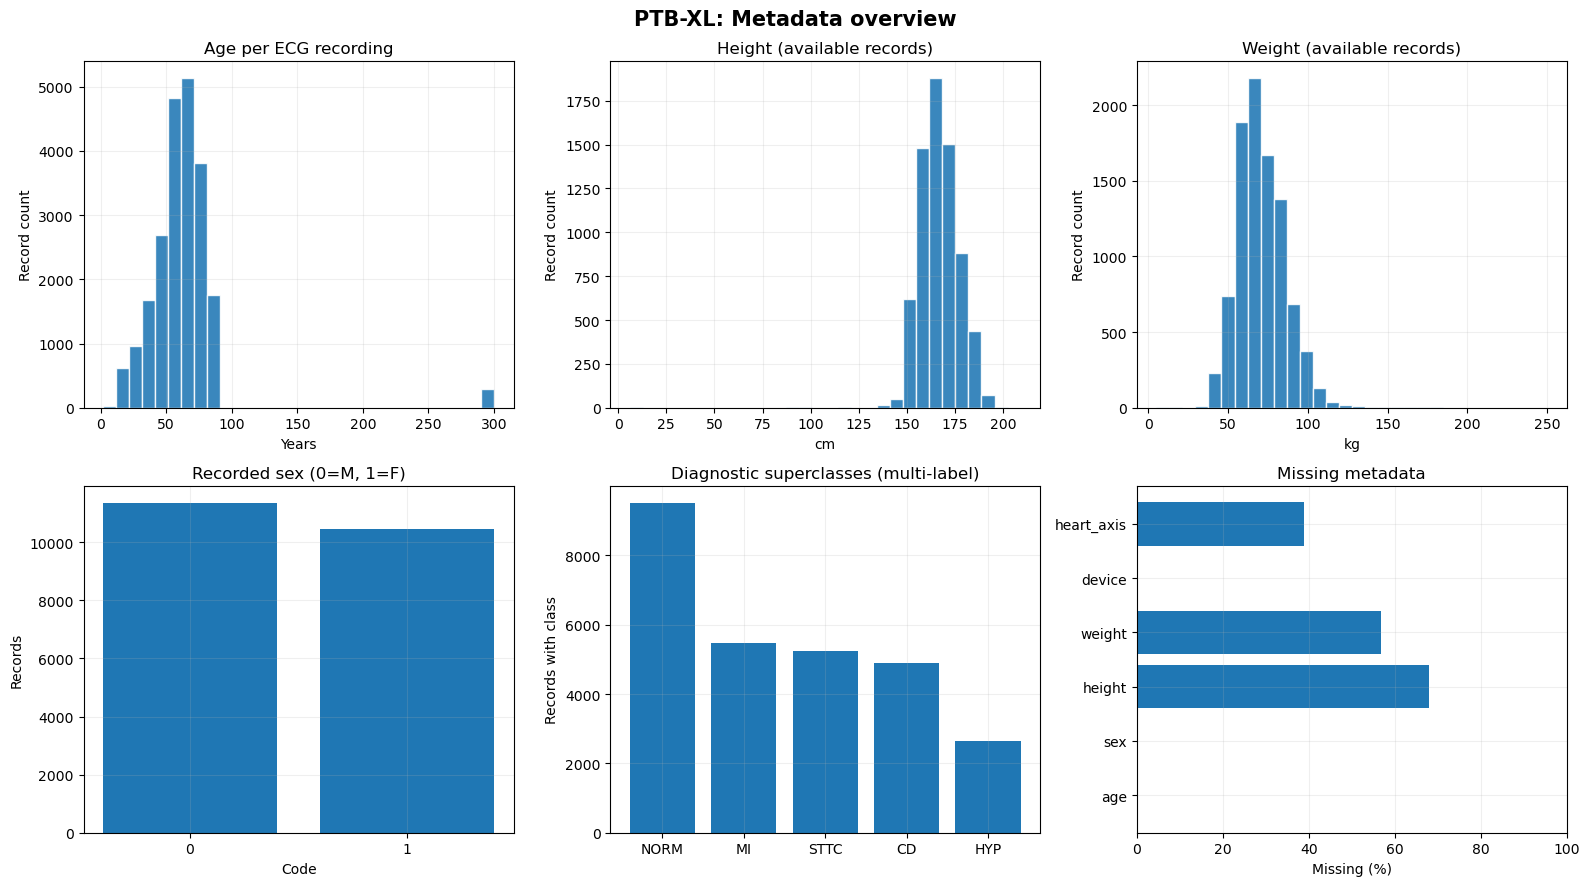

Patient-isolated official folds verified.
Training: 1–8, validation: 9, test: 10.


In [4]:
# Map each SCP code to one of the diagnostic superclasses, when available.
def diagnostic_superclasses(scp_literal):
    try:
        codes = ast.literal_eval(scp_literal) if isinstance(scp_literal, str) else scp_literal
    except (ValueError, SyntaxError, TypeError):
        return set()
    if not isinstance(codes, dict):
        return set()
    result = set()
    for key in codes.keys():
        if str(key) in df_scp.index:
            row = df_scp.loc[str(key)]
            group = row['diagnostic_class']
            if pd.notna(group):
                result.add(str(group))
    return result

all_classes = df['scp_codes'].map(diagnostic_superclasses)
classes = ['NORM', 'MI', 'STTC', 'CD', 'HYP']
class_counts = pd.Series({k: sum(k in rec for rec in all_classes) for k in classes})

print('Diagnostic superclass counts (multi-label):')
print(class_counts.to_string())
print('Records with no diagnostic superclass:', sum(not x for x in all_classes))
print('Counts by recorded sex (0=male, 1=female):')
print(df.sex.value_counts(dropna=False).sort_index().to_string())

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, col, title, unit, bins in [
    (axes[0,0], 'age', 'Age per ECG recording', 'Years', 30),
    (axes[0,1], 'height', 'Height (available records)', 'cm', 30),
    (axes[0,2], 'weight', 'Weight (available records)', 'kg', 30),
]:
    vals = pd.to_numeric(df[col], errors='coerce').dropna()
    if len(vals):
        ax.hist(vals, bins=bins, edgecolor='white', alpha=.88)
    ax.set(title=title, xlabel=unit, ylabel='Record count')
    ax.grid(alpha=.22)

sex = df.sex.value_counts(dropna=False).sort_index()
axes[1,0].bar([str(x) for x in sex.index], sex.to_numpy())
axes[1,0].set(title='Recorded sex (0=M, 1=F)', xlabel='Code', ylabel='Records')
axes[1,1].bar(class_counts.index, class_counts.values)
axes[1,1].set(title='Diagnostic superclasses (multi-label)', ylabel='Records with class')
missing = df.reindex(columns=['age','sex','height','weight','device','heart_axis']).isna().mean()*100
axes[1,2].barh(missing.index, missing.values)
axes[1,2].set(title='Missing metadata', xlabel='Missing (%)', xlim=(0,100))
for ax in axes.ravel():
    ax.grid(alpha=.2)
fig.suptitle('PTB-XL: Metadata overview', fontweight='bold', fontsize=15)
fig.tight_layout()
fig.savefig(OUTPUT_DIR/'01_metadata_eda.png', dpi=150)
plt.show()

# Confirm PTB-XL official patient-isolated fold assignments.
folds_per_patient = df.groupby('patient_id')['strat_fold'].nunique()
assert (folds_per_patient <= 1).all(), 'Patient appears in multiple official folds!'
print('Patient-isolated official folds verified.')
print('Training: 1–8, validation: 9, test: 10.')

## 3 · Select one representative 12-lead recording

Set `ECG_ID` in the first code cell to inspect a different record. Signal shape is `[time, 12]` from WFDB and `[12, time]` in PyTorch.

In [5]:
import wfdb  # pip install wfdb

if ECG_ID is None:
    selected_id = df.index[0]
else:
    selected_id = ECG_ID
selected = df.loc[selected_id]
filename_field = 'filename_hr' if USE_500HZ else 'filename_lr'
record_path = BASE_DIR / str(selected[filename_field])
# WFDB expects the record basename without .hea/.dat
if not (Path(str(record_path) + '.hea')).exists():
    raise FileNotFoundError(
        f'WFDB record not found: {record_path}. '
        f'Ensure the corresponding {"records500" if USE_500HZ else "records100"} directory is extracted.'
    )
signal, meta = wfdb.rdsamp(str(record_path))  # [time, lead], physical units
fs = float(meta['fs'])
lead_names = [str(x) for x in meta.get('sig_name', LEADS)]
if len(lead_names) != 12 or signal.shape[1] != 12:
    raise ValueError(f'Expected 12 leads; received {signal.shape}, names={lead_names}')
if not np.isfinite(signal).all():
    raise ValueError('Signal contains NaN or Infinity. Select another record or define a quality-handling rule.')
if not (0 < LOWCUT < HIGHCUT < fs/2):
    raise ValueError('Bandpass cutoff frequencies must satisfy 0 < low < high < Nyquist.')

# WFDB PTB-XL physical units are mV; verify metadata on your machine.
print('ECG ID:', selected_id, '| Patient:', selected.patient_id)
print('Signal shape:', signal.shape, '| Sample rate:', fs, 'Hz')
print('WFDB units:', meta.get('units'))
print('Diagnostic superclasses:', sorted(diagnostic_superclasses(selected.scp_codes)))

tensor_signal = torch.as_tensor(signal.T.copy(), dtype=torch.float32)
t = np.arange(signal.shape[0]) / fs

ECG ID: 1 | Patient: 15709.0
Signal shape: (1000, 12) | Sample rate: 100.0 Hz
WFDB units: ['mV', 'mV', 'mV', 'mV', 'mV', 'mV', 'mV', 'mV', 'mV', 'mV', 'mV', 'mV']
Diagnostic superclasses: ['NORM']


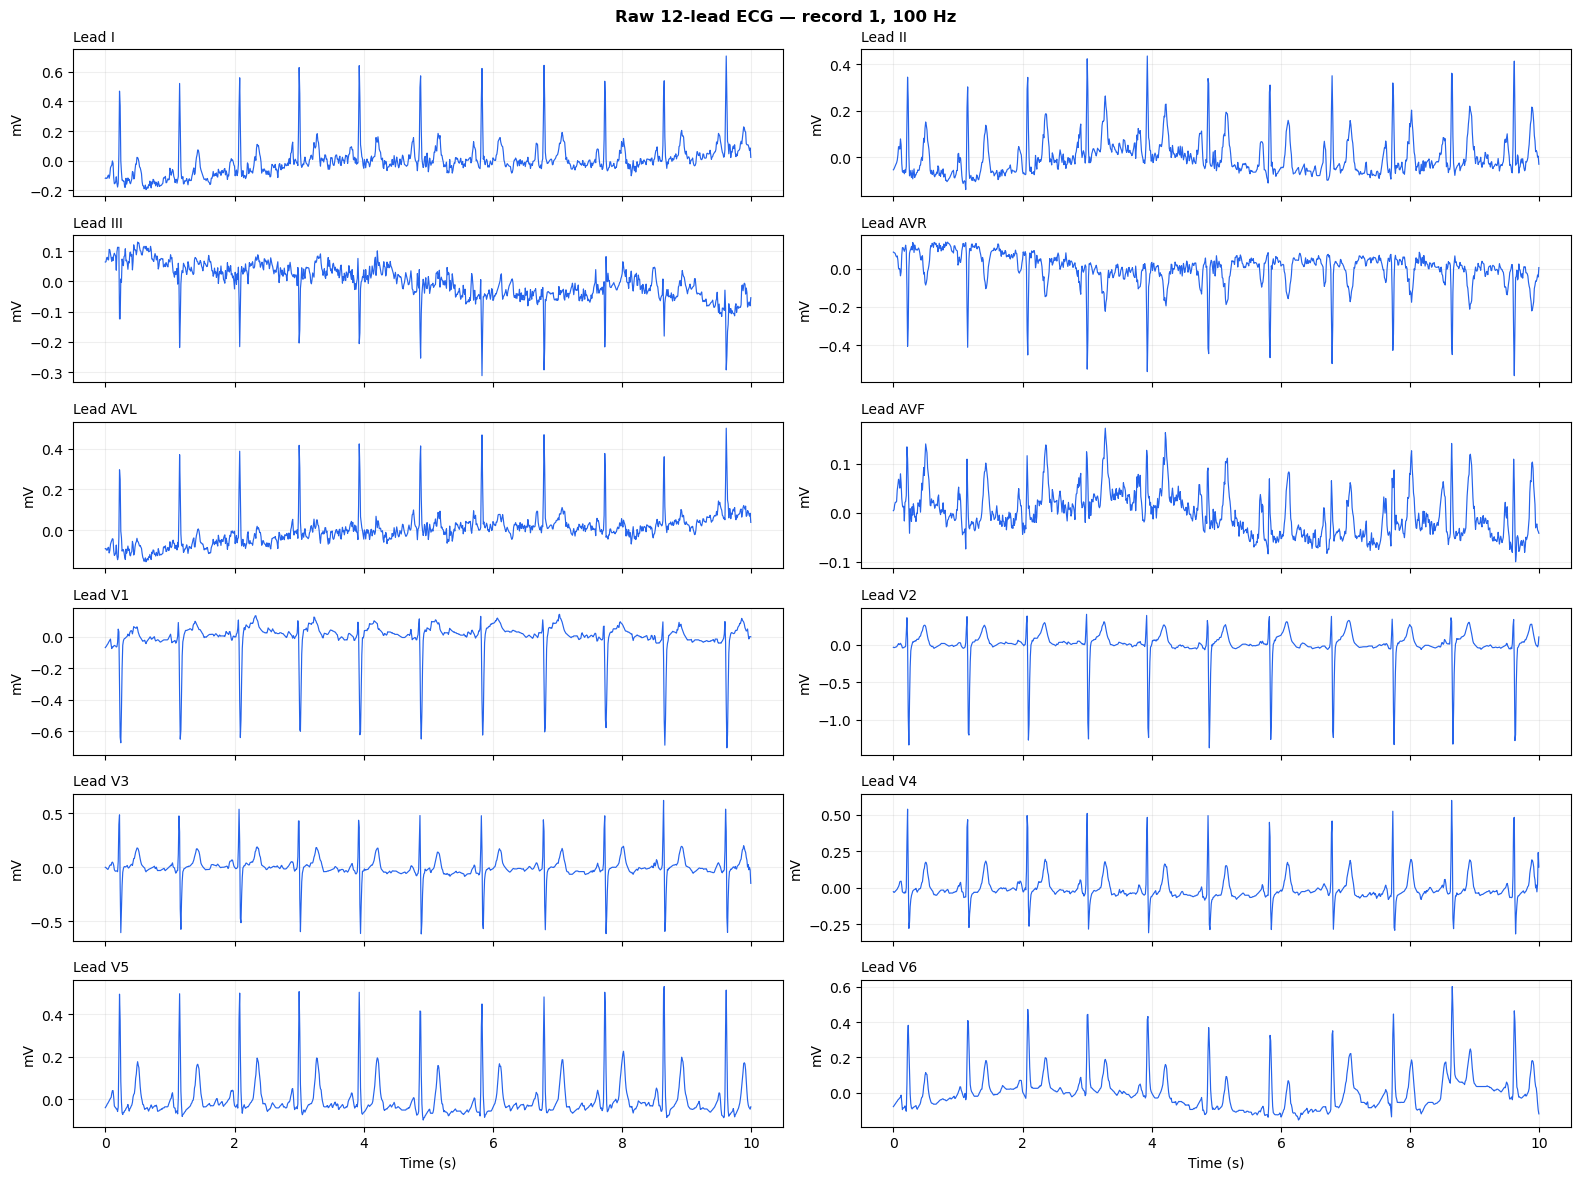

In [6]:
fig, axes = plt.subplots(6, 2, figsize=(16, 12), sharex=True)
for i, ax in enumerate(axes.flat):
    ax.plot(t, signal[:, i], color='#2563eb', linewidth=.85)
    ax.set_title(f'Lead {lead_names[i]}', loc='left', fontsize=10)
    ax.set_ylabel('mV')
    ax.grid(alpha=.2)
for ax in axes[-1,:]: ax.set_xlabel('Time (s)')
fig.suptitle(f'Raw 12-lead ECG — record {selected_id}, {fs:g} Hz', fontweight='bold')
fig.tight_layout()
fig.savefig(OUTPUT_DIR/'02_raw_all_12_leads.png', dpi=150)
plt.show()

## 4 · Exploratory filtering and normalization

A **fourth-order Butterworth bandpass (0.5–40 Hz)** suppresses some low-frequency baseline wander and high-frequency content. We use **second-order sections** (`sosfiltfilt`) for numerical stability. The zero-phase, forward–backward filter uses the **entire recording**, so it is *not* acceptable for a strictly causal forecast input when it can see future target samples.

For predictive modeling, split first and fit normalization on the training data only; consider causally filtering only each observed window, and apply any target transformation consistently without using target information in inputs.

In [7]:
def filter_record(signal_t_by_l, fs, low=0.5, high=40.0, order=4):
    sos = butter(order, [low, high], btype='bandpass', fs=fs, output='sos')
    return sosfiltfilt(sos, signal_t_by_l, axis=0)

filtered = filter_record(signal, fs, LOWCUT, HIGHCUT)
residual = signal - filtered  # Difference from the filter, NOT a ground-truth noise signal
filtered_tensor = torch.as_tensor(filtered.T.copy(), dtype=torch.float32)

# Only for visualization / offline EDA, not valid forecasting input normalization.
mu = filtered_tensor.mean(dim=1, keepdim=True)
sigma = filtered_tensor.std(dim=1, keepdim=True).clamp_min(1e-5)
processed_tensor = (filtered_tensor - mu) / sigma
print('Raw tensor:', tuple(tensor_signal.shape), 'Filtered:', tuple(filtered_tensor.shape),
      'Visual z-score:', tuple(processed_tensor.shape))

Raw tensor: (12, 1000) Filtered: (12, 1000) Visual z-score: (12, 1000)


## 5 · Before and after preprocessing — **all 12 leads**

Both curves are in **mV**, on the same axis, so we see the actual size of the changes. Avoid plotting raw mV together with z-scores: that would mix units and exaggerate or mask filter effects.

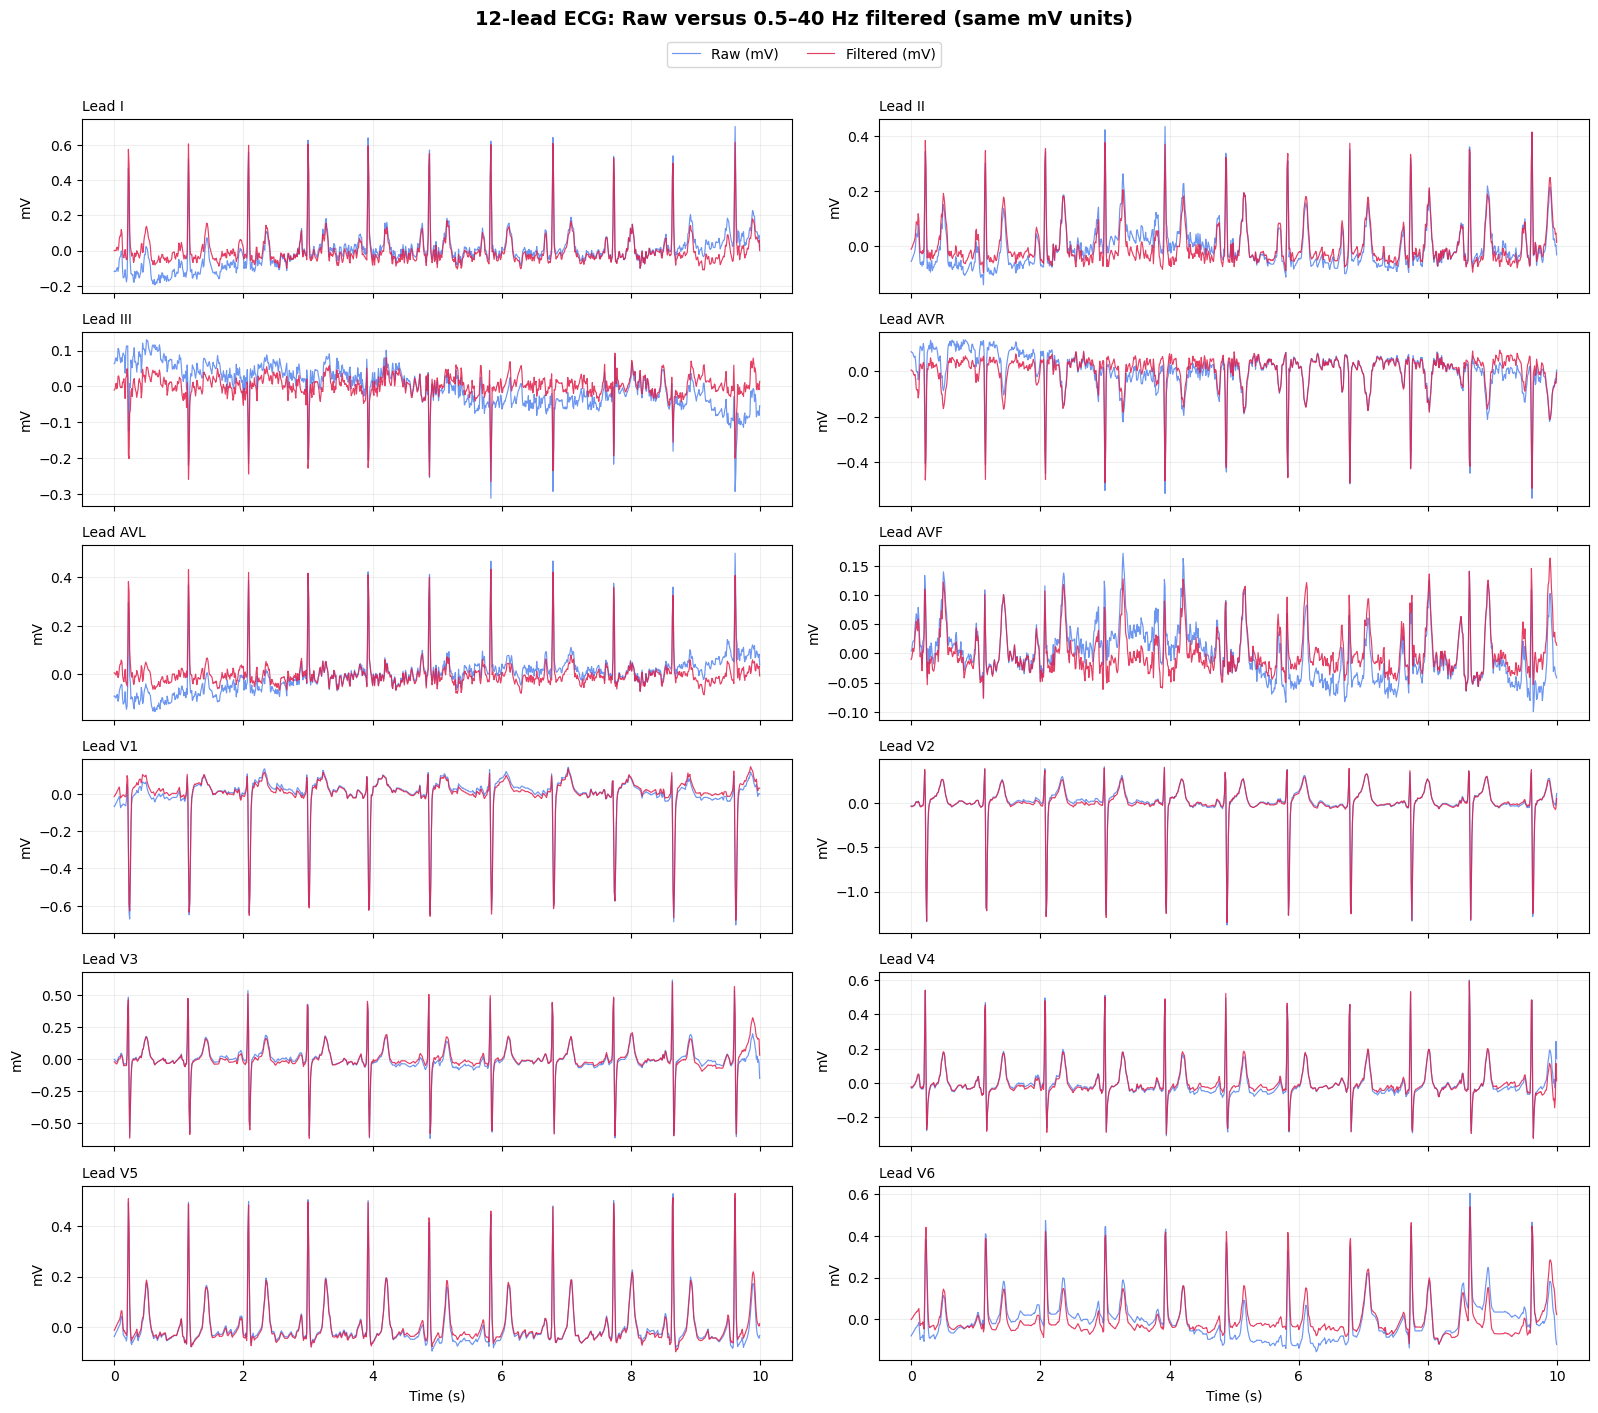

In [8]:
fig, axes = plt.subplots(6, 2, figsize=(16, 14), sharex=True)
for i, ax in enumerate(axes.flat):
    ax.plot(t, signal[:,i], color='#2563eb', alpha=.67, linewidth=.85, label='Raw (mV)')
    ax.plot(t, filtered[:,i], color='#e11d48', alpha=.85, linewidth=.85, label='Filtered (mV)')
    ax.set_title(f'Lead {lead_names[i]}', loc='left', fontsize=10)
    ax.set_ylabel('mV')
    ax.grid(alpha=.2)
for ax in axes[-1,:]: ax.set_xlabel('Time (s)')
handles, labels = axes[0,0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper center', ncol=2, bbox_to_anchor=(.5,.988))
fig.suptitle('12-lead ECG: Raw versus 0.5–40 Hz filtered (same mV units)', y=1.006, fontsize=14, fontweight='bold')
fig.tight_layout(rect=[0,0,1,.977])
fig.savefig(OUTPUT_DIR/'03_before_after_all_leads.png', dpi=150, bbox_inches='tight')
plt.show()

## 6 · What did the filter remove? Residual on every lead

The residual is **raw minus filtered**. It can contain baseline drift and interference but may also include physiologically meaningful content near the stopbands. Do not interpret all residual energy as noise, or call the filter beneficial solely because it reduces the amplitude.

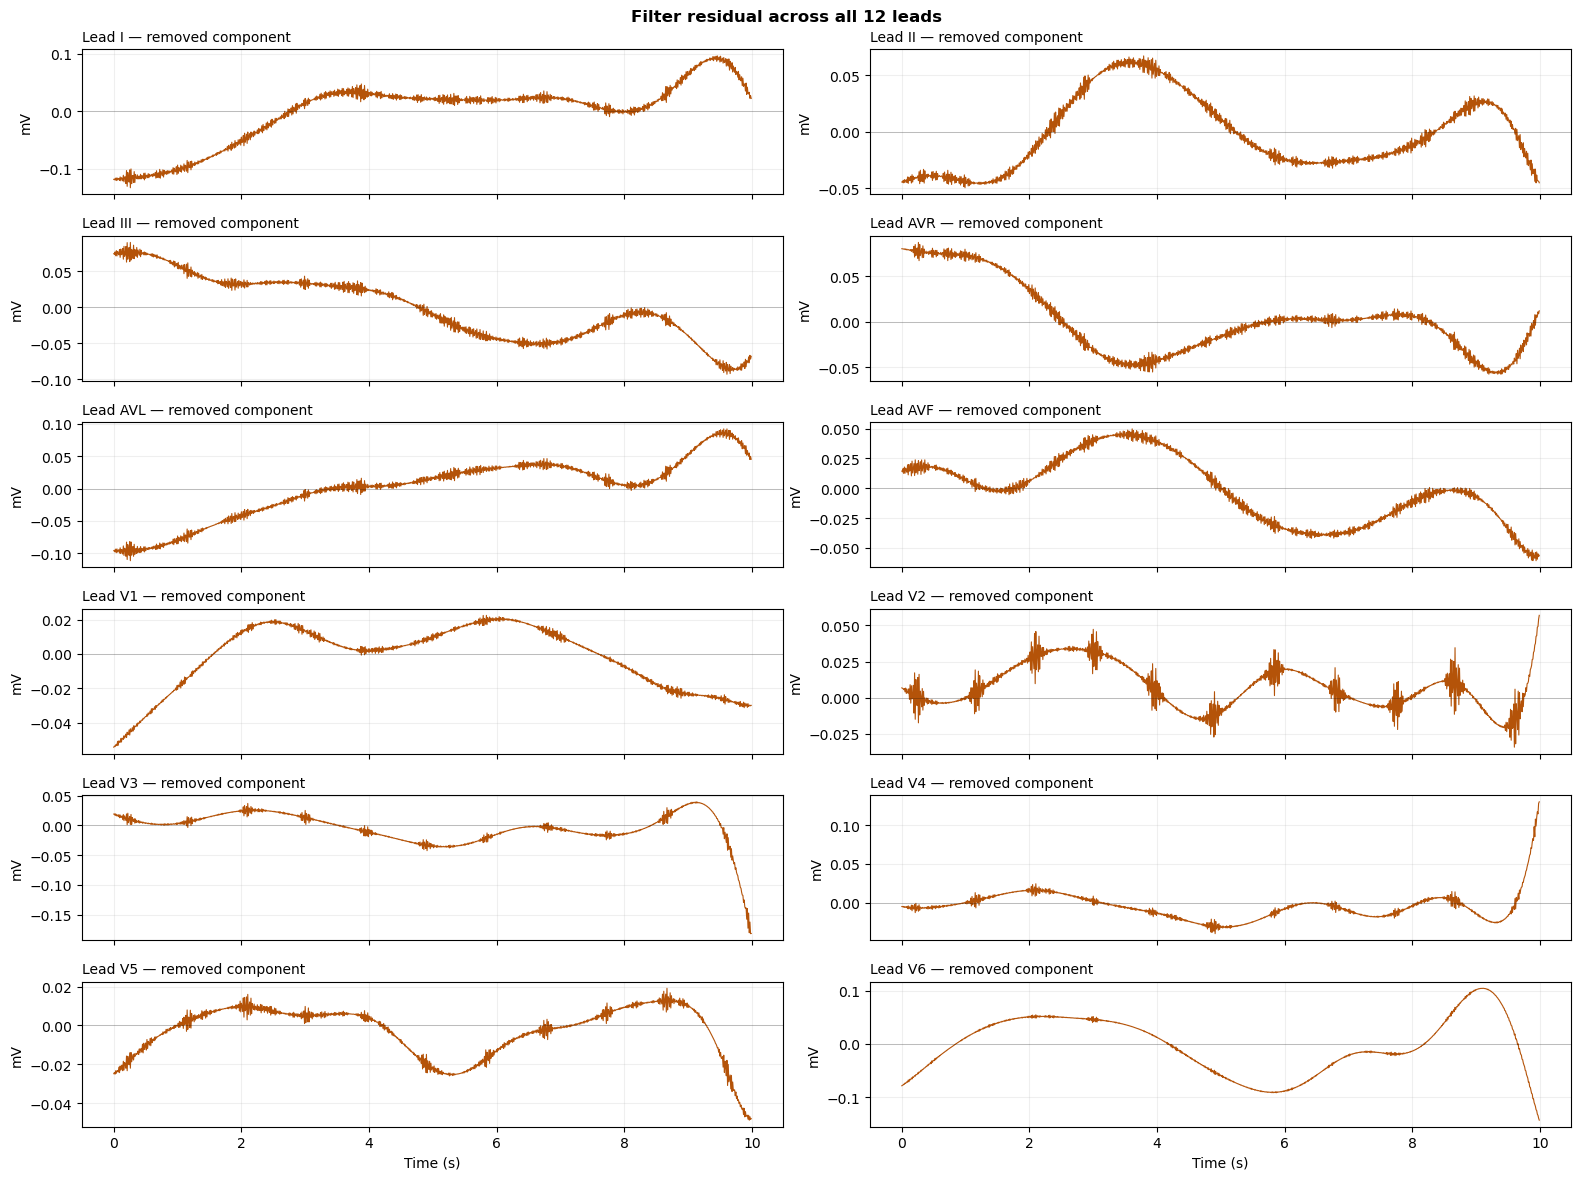

In [9]:
fig, axes = plt.subplots(6, 2, figsize=(16, 12), sharex=True)
for i, ax in enumerate(axes.flat):
    ax.plot(t, residual[:,i], color='#b45309', linewidth=.8)
    ax.axhline(0, color='black', alpha=.3, lw=.5)
    ax.set_title(f'Lead {lead_names[i]} — removed component', loc='left', fontsize=10)
    ax.set_ylabel('mV')
    ax.grid(alpha=.2)
for ax in axes[-1,:]: ax.set_xlabel('Time (s)')
fig.suptitle('Filter residual across all 12 leads', fontweight='bold')
fig.tight_layout()
fig.savefig(OUTPUT_DIR/'04_filter_residual_all_leads.png', dpi=150)
plt.show()

## 7 · Frequency-domain evidence: Welch PSD for all 12 leads

Welch's method estimates **power spectral density** in mV²/Hz (unlike an unnormalized FFT magnitude squared, which is not a PSD). Compare the raw and filtered spectra using exactly the same Welch parameters.

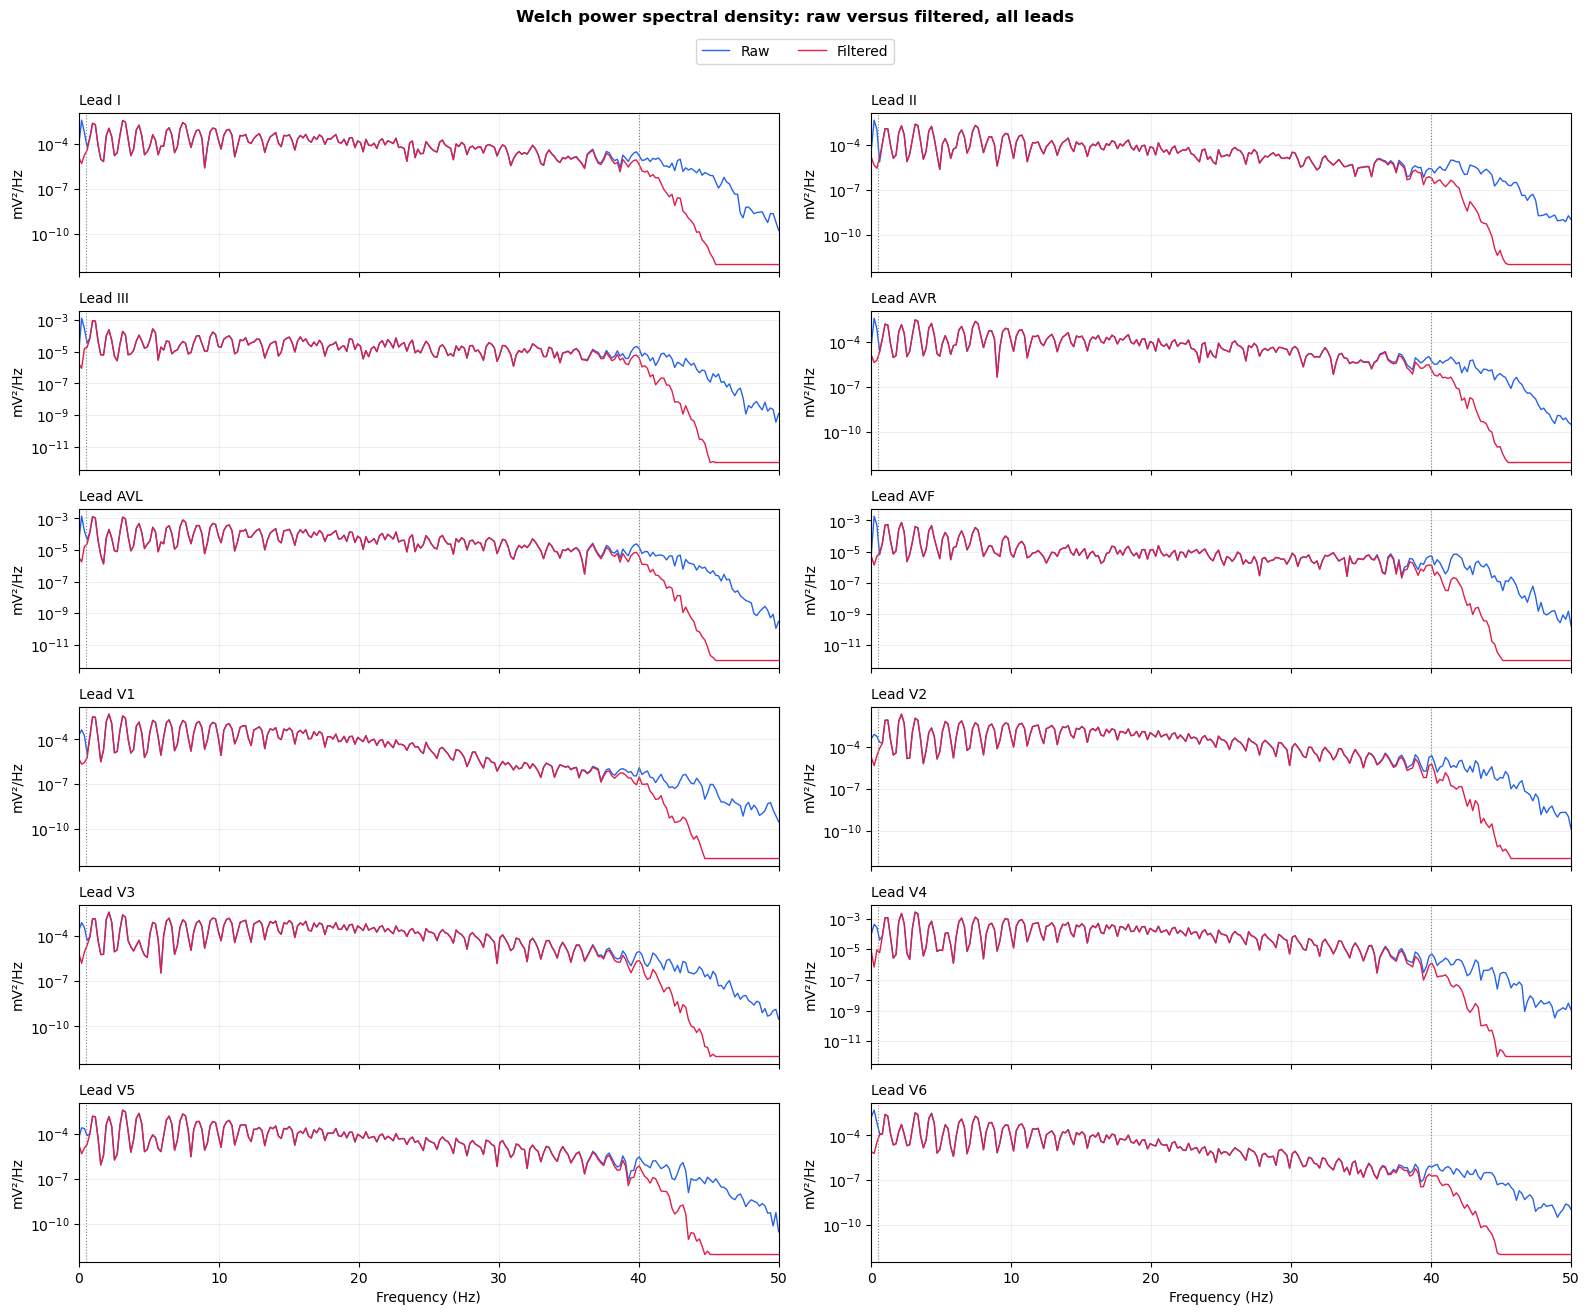

In [15]:
nperseg = min(512, signal.shape[0])
freq, psd_raw = welch(signal, fs=fs, nperseg=nperseg, axis=0)
_, psd_filtered = welch(filtered, fs=fs, nperseg=nperseg, axis=0)

fig, axes = plt.subplots(6, 2, figsize=(16, 13), sharex=True)
for i, ax in enumerate(axes.flat):
    ax.semilogy(freq, np.maximum(psd_raw[:,i], 1e-12), color='#2563eb', lw=1, label='Raw')
    ax.semilogy(freq, np.maximum(psd_filtered[:,i], 1e-12), color='#e11d48', lw=1, label='Filtered')
    ax.axvline(LOWCUT, color='gray', ls=':', lw=.8)
    ax.axvline(HIGHCUT, color='gray', ls=':', lw=.8)
    ax.set_title(f'Lead {lead_names[i]}', loc='left', fontsize=10)
    ax.set_ylabel('mV²/Hz')
    ax.grid(alpha=.2, which='both')
    ax.set_xlim(0, fs/2)
for ax in axes[-1,:]: ax.set_xlabel('Frequency (Hz)')
handles, labels = axes[0,0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper center', ncol=2, bbox_to_anchor=(.5,.991))
fig.suptitle('Welch power spectral density: raw versus filtered, all leads', y=1.008, fontweight='bold')
fig.tight_layout(rect=[0,0,1,.978])
fig.savefig(OUTPUT_DIR/'05_welch_psd_all_leads.png', dpi=150, bbox_inches='tight')
plt.show()

## 8 · Quantify the effect for every lead

Report root-mean-square amplitude and change from the filter, samplewise Pearson agreement and broad-band power before/after. These values quantify *change*, not clinical accuracy or signal-to-noise improvement. Values use the same selected ECG only.

,lead,raw_rms_mV,filtered_rms_mV,residual_rms_mV,residual_rms_pct_of_raw,raw_vs_filtered_pearson,raw_low_band_power_mV2,filtered_low_band_power_mV2,raw_high_band_power_mV2,filtered_high_band_power_mV2
0,I,0.10903,0.09541,0.05415,49.66711,0.86798,0.00075,0.00000,0.00003,0.0
1,II,0.08323,0.07834,0.03276,39.36331,0.91982,0.00093,0.00000,0.00001,0.0
2,III,0.05873,0.03853,0.04375,74.49319,0.66740,0.00029,0.00000,0.00002,0.0
3,AVR,0.09239,0.08511,0.03897,42.18460,0.90690,0.00077,0.00000,0.00002,0.0
4,AVL,0.07698,0.06122,0.04639,60.26046,0.79799,0.00029,0.00000,0.00002,0.0
5,AVF,0.04686,0.03904,0.02741,58.49642,0.81194,0.00042,0.00000,0.00001,0.0
6,V1,0.11313,0.11155,0.01865,16.48475,0.98648,0.00012,0.00000,0.00000,0.0
7,V2,0.21434,0.21325,0.01712,7.98802,0.99742,0.00023,0.00000,0.00002,0.0
8,V3,0.11785,0.11992,0.02849,24.17439,0.97218,0.00021,0.00000,0.00001,0.0
9,V4,0.09550,0.09385,0.01923,20.13557,0.98053,0.00012,0.00000,0.00001,0.0


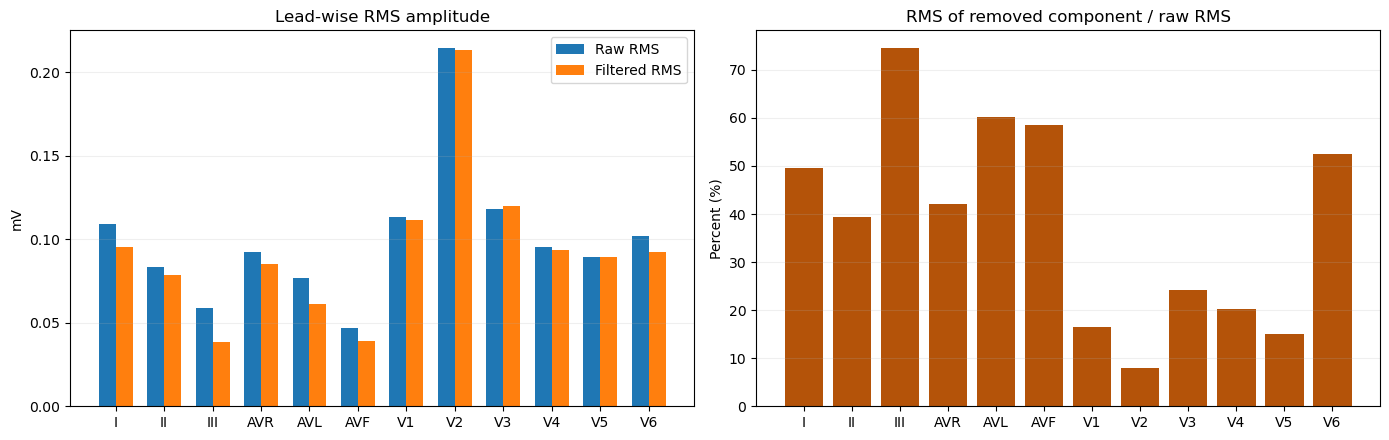

In [11]:
def rms(x):
    return float(np.sqrt(np.mean(np.asarray(x, dtype=float)**2)))

# Recompute spectra here so this cell does not depend on the PSD plot cell's state.
nperseg = min(512, signal.shape[0])
freq, psd_raw = welch(signal, fs=fs, nperseg=nperseg, axis=0)
_, psd_filtered = welch(filtered, fs=fs, nperseg=nperseg, axis=0)

def band_power(psd, left, right):
    mask = (freq >= left) & (freq <= right)
    return float(np.trapezoid(psd[mask], x=freq[mask])) if mask.sum() >= 2 else np.nan

rows = []
for i, name in enumerate(lead_names):
    corr = np.corrcoef(signal[:,i], filtered[:,i])[0,1]
    rows.append({
        'lead': name,
        'raw_rms_mV': rms(signal[:,i]),
        'filtered_rms_mV': rms(filtered[:,i]),
        'residual_rms_mV': rms(residual[:,i]),
        'residual_rms_pct_of_raw': 100*rms(residual[:,i])/max(rms(signal[:,i]),1e-9),
        'raw_vs_filtered_pearson': float(corr),
        'raw_low_band_power_mV2': band_power(psd_raw[:,i], 0, LOWCUT),
        'filtered_low_band_power_mV2': band_power(psd_filtered[:,i], 0, LOWCUT),
        'raw_high_band_power_mV2': band_power(psd_raw[:,i], HIGHCUT, fs/2),
        'filtered_high_band_power_mV2': band_power(psd_filtered[:,i], HIGHCUT, fs/2),
    })
impact_df = pd.DataFrame(rows)
display(impact_df.round(5))
impact_df.to_csv(OUTPUT_DIR/'Lead_Wise_Preprocessing_Impact.csv', index=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
x = np.arange(12)
width=.35
axes[0].bar(x-width/2, impact_df.raw_rms_mV, width, label='Raw RMS')
axes[0].bar(x+width/2, impact_df.filtered_rms_mV, width, label='Filtered RMS')
axes[0].set(title='Lead-wise RMS amplitude', ylabel='mV', xticks=x, xticklabels=lead_names)
axes[0].legend()
axes[1].bar(lead_names, impact_df.residual_rms_pct_of_raw, color='#b45309')
axes[1].set(title='RMS of removed component / raw RMS', ylabel='Percent (%)')
for ax in axes: ax.grid(alpha=.2, axis='y')
fig.tight_layout()
fig.savefig(OUTPUT_DIR/'06_quantified_preprocessing.png', dpi=150)
plt.show()

## 9 · Zoom in on a high-amplitude event (Lead II)

A ~1-second segment around the largest absolute deflection in Lead II is useful for checking whether sharp features are attenuated or distorted. **This is not a verified R-peak detector**: a large artifact could also be selected.

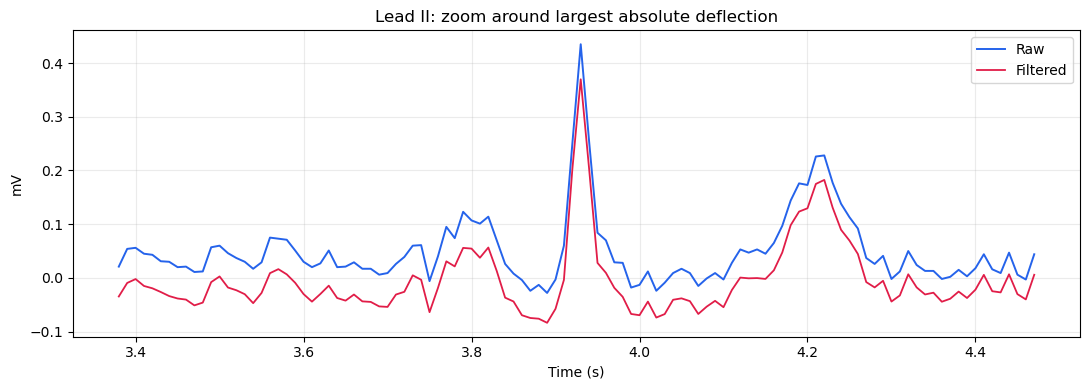

In [12]:
lead_ii = lead_names.index('II') if 'II' in lead_names else 1
center = int(np.argmax(np.abs(signal[:,lead_ii] - np.median(signal[:,lead_ii]))))
start = max(0, center - int(.55*fs))
stop = min(len(t), center + int(.55*fs))
fig, ax = plt.subplots(figsize=(11,4))
ax.plot(t[start:stop], signal[start:stop,lead_ii], label='Raw', color='#2563eb', lw=1.4)
ax.plot(t[start:stop], filtered[start:stop,lead_ii], label='Filtered', color='#e11d48', lw=1.3)
ax.set(title='Lead II: zoom around largest absolute deflection', xlabel='Time (s)', ylabel='mV')
ax.legend()
ax.grid(alpha=.25)
fig.tight_layout()
fig.savefig(OUTPUT_DIR/'07_lead_II_event_zoom.png', dpi=150)
plt.show()

## 10 · Inter-lead correlation before and after processing

Correlations across ECG leads can be high or negative because lead measurements have shared and related electrical origins. Correlation change by itself does not indicate improved performance.

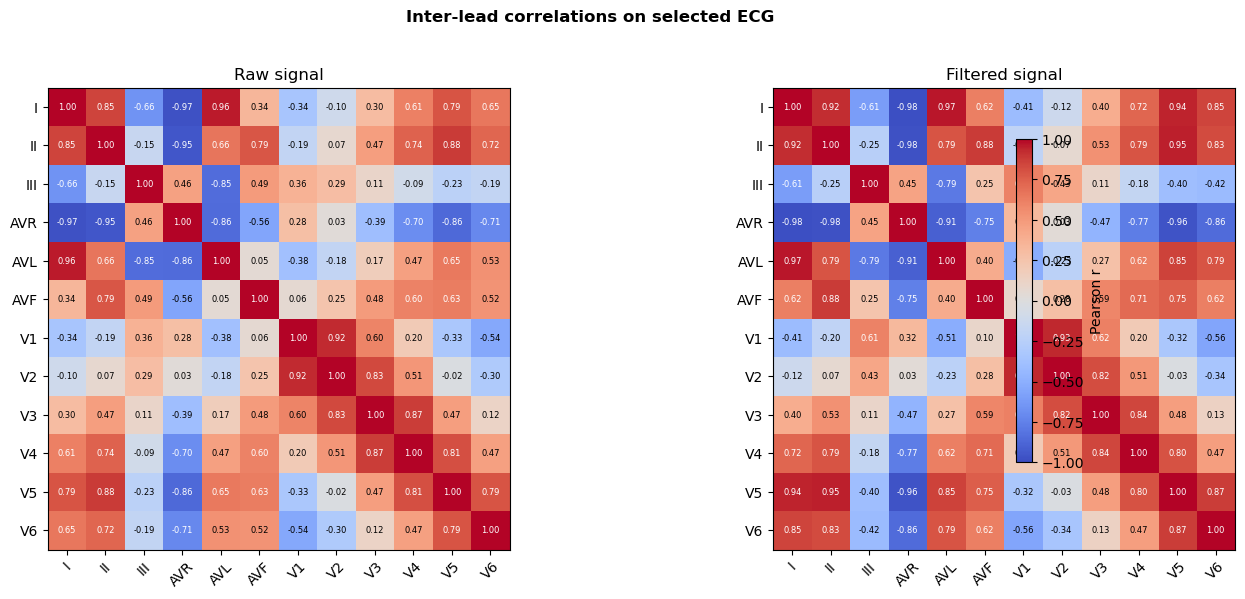

In [13]:
corr_before = pd.DataFrame(signal, columns=lead_names).corr()
corr_after = pd.DataFrame(filtered, columns=lead_names).corr()
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, mat, title in zip(axes, [corr_before, corr_after], ['Raw signal', 'Filtered signal']):
    im=ax.imshow(mat, vmin=-1, vmax=1, cmap='coolwarm')
    ax.set(xticks=range(12), yticks=range(12),
           xticklabels=lead_names, yticklabels=lead_names, title=title)
    ax.tick_params(axis='x', rotation=45)
    for i in range(12):
        for j in range(12):
            ax.text(j, i, f'{mat.iloc[i,j]:.2f}', ha='center', va='center', fontsize=6,
                    color='white' if abs(mat.iloc[i,j])>.6 else 'black')
fig.colorbar(im, ax=axes.ravel().tolist(), shrink=.7, label='Pearson r')
fig.suptitle('Inter-lead correlations on selected ECG', fontweight='bold')
fig.subplots_adjust(left=.05,right=.93,bottom=.08,top=.85,wspace=.22)
fig.savefig(OUTPUT_DIR/'08_lead_correlation_comparison.png', dpi=150, bbox_inches='tight')
plt.show()